# 01 Data Audit
**Real Planet or False Alarm? Classifying Kepler Exoplanet Candidates**  
Keelan O'Dowd (23440916)

Before building any model I want to really understand the KOI table: what each column means, what's missing, what looks strange and, most of all, what could leak the answer. This notebook ends with the final feature list and drop list, which live in `src/features.py`.

Structural checks use the whole table. Anything that uses the labels to make a decision only uses the training set, after the split in section 5.

## 0. Setup

In [73]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

from src.data import load_data
from src.features import (CORE_FEATURES, FEATURE_UNITS, GROUP, ID_COLUMNS, LEAKY_COLUMNS,
                          LEAKY_PREFIXES, LINEAR_FEATURES, NEGATIVE_LABEL, POSITIVE_LABEL,
                          SENSITIVITY_FEATURES, TARGET, is_leaky)

RANDOM_STATE = 42
REPORTS = ROOT / "reports"
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = {1: "#2a78d6", 0: "#eb6834"}
CLASS_NAMES = {1: "Confirmed", 0: "False positive"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

## 1. Load the data

The first run downloads the table from the NASA Exoplanet Archive and prints its SHA-256 fingerprint. After that the local copy is used and checked against that fingerprint, so every run uses exactly the same data.

In [74]:
df = load_data()
print("Shape:", df.shape)

Shape: (9564, 153)


### What is one row, and when do we predict?

* **One row is one KOI**, a repeating dip in a star's brightness that might be a planet.
* **KOIs belong to stars.** One star can have up to 7, and they all share that star's values, so every split keeps a star's KOIs together.
* **The prediction moment** is after the transit has been fitted and the star measured, but before NASA vets it or anyone does follow-up observations. Anything produced at or after vetting counts as leakage.
* **No time split.** There's no usable discovery date for each KOI, and `koi_delivname` has a single value, so every row comes from one final processing run. The one exception, older stellar data, is looked at in section 8C.

## 2. Column roles

Each of the 153 columns gets a role, assigned by rule from `src/features.py` so the result is reproducible. Anything that doesn't match a rule shows up as `other numeric` or `text/other` so I can check it by hand. The saved dictionary in `reports/data_dictionary.csv` also records each column's type, units for the model features, and whether it's available at prediction time.

In [75]:
METADATA_PREFIXES = ("koi_datalink", "koi_delivname", "koi_tce_delivname", "koi_quarters",
                     "koi_limbdark_mod", "koi_trans_mod", "koi_parm_prov", "koi_sparprov",
                     "koi_fittype")


def column_role(col):
    """First matching rule wins, so the order of these checks matters."""
    s = df[col]
    if s.isna().all():
        return "empty"
    if s.nunique(dropna=True) <= 1:
        return "constant"
    if col == TARGET:
        return "target"
    if col in ID_COLUMNS:
        return "id"
    if is_leaky(col):
        return "leak"
    if col.startswith(METADATA_PREFIXES):
        return "metadata"
    if col in CORE_FEATURES:
        return "core feature"
    if col in SENSITIVITY_FEATURES:
        return "sensitivity"
    if not pd.api.types.is_numeric_dtype(s):
        return "text/other"
    return "other numeric"


def conceptual_type(col):
    s = df[col]
    if col in ID_COLUMNS:
        return "identifier"
    if col == TARGET:
        return "target (nominal)"
    if col.endswith("_date"):
        return "temporal"
    if pd.api.types.is_numeric_dtype(s):
        return "binary" if s.nunique(dropna=True) == 2 else "numerical"
    return "nominal / text"


dictionary = pd.DataFrame({
    "column": df.columns,
    "conceptual_type": [conceptual_type(c) for c in df.columns],
    "dtype": df.dtypes.astype(str).values,
    "role": [column_role(c) for c in df.columns],
    "units": pd.Series(df.columns).map(FEATURE_UNITS).fillna("").values,
    "available_at_prediction": [not is_leaky(c) and c != TARGET for c in df.columns],
    "missing_pct": (df.isna().mean() * 100).round(1).values,
    "n_unique": df.nunique().values,
})

dictionary.to_csv(REPORTS / "data_dictionary.csv", index=False)
dictionary["role"].value_counts()

role
other numeric    52
leak             40
empty            24
core feature     13
constant         11
metadata          7
id                4
target            1
sensitivity       1
Name: count, dtype: int64

In [76]:
#columns outside the core set to check by hand
dictionary[dictionary["role"].isin(["other numeric", "text/other"])]

,column,conceptual_type,dtype,role,units,available_at_prediction,missing_pct,n_unique
3,ra,numerical,float64,other numeric,,True,0.0,8131
6,dec,numerical,float64,other numeric,,True,0.0,8195
9,koi_gmag,numerical,float64,other numeric,,True,0.4,4178
11,koi_rmag,numerical,float64,other numeric,,True,0.1,3917
13,koi_imag,numerical,float64,other numeric,,True,1.6,3743
15,koi_zmag,numerical,float64,other numeric,,True,6.4,3555
17,koi_jmag,numerical,float64,other numeric,,True,0.3,3743
18,koi_jmag_err,numerical,float64,other numeric,,True,0.8,101
19,koi_hmag,numerical,float64,other numeric,,True,0.3,3736
20,koi_hmag_err,numerical,float64,other numeric,,True,1.0,123


Nothing ended up as `text/other`, so every text column is covered by a rule. The 52 `other numeric` columns are left out on purpose to keep the feature set small and explainable. They're mostly uncertainties on fitted values, extra fit parameters that overlap with the core features like `koi_ror` and `koi_sma`, pipeline detection statistics, limb darkening coefficients, brightness in other bands, and sky position. A few of them score highly on their own in section 8B, so I deal with those there.

## 3. Structural checks

In [77]:
non_numeric = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]

checks = {
    "exact duplicate rows": int(df.duplicated().sum()),
    "duplicate kepoi_name": int(df["kepoi_name"].duplicated().sum()),
    "empty columns": int((dictionary["role"] == "empty").sum()),
    "constant columns": int((dictionary["role"] == "constant").sum()),
    "non-numeric columns": len(non_numeric),
}
assert checks["duplicate kepoi_name"] == 0
pd.Series(checks, name="count").to_frame()

,count
exact duplicate rows,0
duplicate kepoi_name,0
empty columns,24
constant columns,11
non-numeric columns,20


In [78]:
print("Column types:", df.dtypes.astype(str).value_counts().to_dict())
print("Empty:", dictionary.loc[dictionary["role"] == "empty", "column"].tolist())
print("Constant:", dictionary.loc[dictionary["role"] == "constant", "column"].tolist())

Column types: {'float64': 127, 'str': 19, 'int64': 6, 'object': 1}
Empty: ['koi_gmag_err', 'koi_rmag_err', 'koi_imag_err', 'koi_zmag_err', 'koi_kepmag_err', 'koi_model_dof', 'koi_model_chisq', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_sma_err1', 'koi_sma_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_sage', 'koi_sage_err1', 'koi_sage_err2']
Constant: ['ra_err', 'dec_err', 'koi_delivname', 'koi_vet_stat', 'koi_limbdark_mod', 'koi_ldm_coeff4', 'koi_ldm_coeff3', 'koi_trans_mod', 'koi_eccen', 'koi_vet_date', 'koi_disp_prov']


No duplicate rows and no duplicate `kepoi_name`, so every row is a different KOI. 24 columns are completely empty and 11 hold just one value, like `koi_eccen`, which suggests every orbit was fitted as circular. Neither group tells a model anything, so they're dropped. That leaves 133 numeric and 20 text columns, and every text column is an ID, metadata, a leak or the target, so there's nothing to encode.

## 4. Target and groups

Stars: 8,214 | stars with >1 KOI: 938


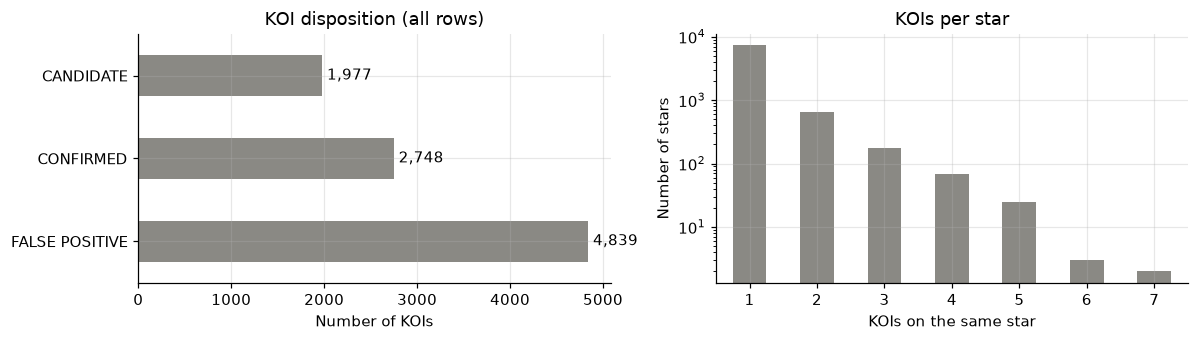

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))

counts = df[TARGET].value_counts()
counts.plot.barh(ax=axes[0], color="#8a8984")
axes[0].set(title="KOI disposition (all rows)", xlabel="Number of KOIs", ylabel="")
for i, v in enumerate(counts):
    axes[0].text(v, i, f" {v:,}", va="center")

koi_per_star = df.groupby(GROUP).size().value_counts().sort_index()
koi_per_star.plot.bar(ax=axes[1], color="#8a8984", rot=0)
axes[1].set(title="KOIs per star", xlabel="KOIs on the same star", ylabel="Number of stars",
            yscale="log")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_target_and_groups.png", bbox_inches="tight")
print(f"Stars: {df[GROUP].nunique():,} | stars with >1 KOI: {(df.groupby(GROUP).size() > 1).sum():,}")

In [ ]:
labelled = df[df[TARGET].isin([POSITIVE_LABEL, NEGATIVE_LABEL])].copy()
labelled["y"] = (labelled[TARGET] == POSITIVE_LABEL).astype(int)
n_candidates = (df[TARGET] == "CANDIDATE").sum()

prevalence = labelled["y"].mean()
print(f"Labelled rows: {len(labelled):,} | candidates set aside: {n_candidates:,}")
print(f"Prevalence (share confirmed): {prevalence:.3f}")

Labelled rows: 7,587 | candidates set aside: 1,977
Prevalence (share confirmed): 0.362


7,587 KOIs have a label and 36.2% of them are confirmed planets. That's imbalanced enough that accuracy would be misleading, since answering "false positive" every time already scores 63.8%. So PR-AUC is my main metric, and a model with no skill scores 0.362 on it. The 1,977 candidates have no answer yet, so they're set aside.

938 of the 8,214 stars have more than one KOI. Those KOIs share all their stellar values, so with a random split a model could recognise the star instead of learning anything about the signal. That's why every split is grouped by star.

## 5. Train/test split

An 80/20 split, grouped by star and stratified so both sides have the same share of planets. It's saved to `data/split.csv` so every later notebook uses exactly the same rows.

**From here on the test set isn't touched until the final evaluation.**

In [ ]:
stratified_group_k_fold = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
_, test_idx = next(stratified_group_k_fold.split(labelled, labelled["y"], groups=labelled[GROUP]))
labelled["set"] = "train"
labelled.loc[labelled.index[test_idx], "set"] = "test"

train = labelled[labelled["set"] == "train"].copy()
test = labelled[labelled["set"] == "test"]

assert set(train[GROUP]).isdisjoint(test[GROUP]), "a star appears in both train and test"
assert abs(train["y"].mean() - test["y"].mean()) < 0.02, "class ratio differs between sets"
assert 0.18 < len(test) / len(labelled) < 0.22, "test size is far from 20%"

split_summary = labelled.groupby("set").agg(rows=("y", "size"), stars=(GROUP, "nunique"),
                                            share_confirmed=("y", "mean"))
split_summary["share_of_rows"] = split_summary["rows"] / len(labelled)
labelled[["kepoi_name", "set"]].to_csv(ROOT / "data" / "split.csv", index=False)

split_summary.round(3)

,rows,stars,share_confirmed,share_of_rows
set,,,,
test,1519,1335,0.362,0.2
train,6068,5306,0.362,0.8


## 6. Missing values

Training set only, and only the columns that could go into a model, since everything else is dropped anyway.

,overall_%,confirmed_%,false_positive_%
koi_num_transits,8.78,0.41,13.54
koi_model_snr,3.41,0.09,5.30
koi_impact,3.41,0.09,5.30
koi_srad,3.41,0.09,5.30
koi_depth,3.41,0.09,5.30
koi_teq,3.41,0.09,5.30
koi_steff,3.41,0.09,5.30
koi_prad,3.41,0.09,5.30
koi_slogg,3.41,0.09,5.30
koi_insol,2.85,0.05,4.44


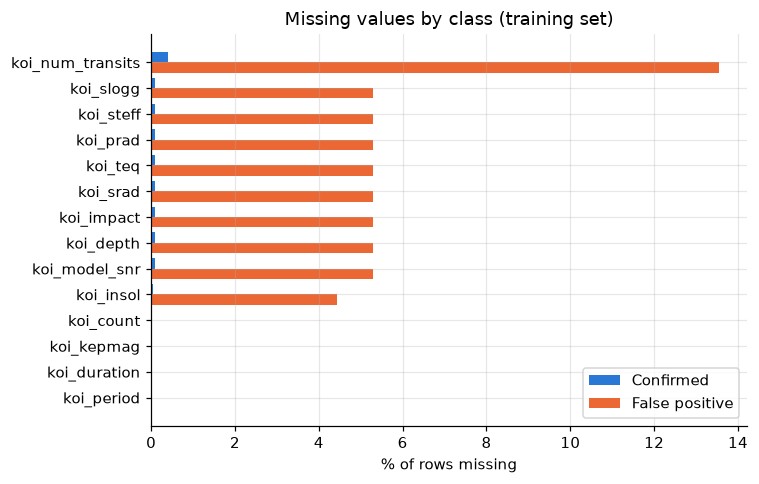

In [ ]:
model_feature_columns = CORE_FEATURES + SENSITIVITY_FEATURES
is_confirmed = train["y"] == 1
missing = pd.DataFrame({
    "overall_%": train[model_feature_columns].isna().mean() * 100,
    "confirmed_%": train.loc[is_confirmed, model_feature_columns].isna().mean() * 100,
    "false_positive_%": train.loc[~is_confirmed, model_feature_columns].isna().mean() * 100,
}).sort_values("overall_%")

fig, ax = plt.subplots(figsize=(7, 4.5))
ypos = np.arange(len(missing))
ax.barh(ypos + 0.2, missing["confirmed_%"], height=0.4, color=CLASS_COLORS[1], label=CLASS_NAMES[1])
ax.barh(ypos - 0.2, missing["false_positive_%"], height=0.4, color=CLASS_COLORS[0], label=CLASS_NAMES[0])
ax.set(yticks=ypos, yticklabels=missing.index, xlabel="% of rows missing",
       title="Missing values by class (training set)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_missing_by_class.png", bbox_inches="tight")
missing.round(2).sort_values("overall_%", ascending=False)

In [ ]:
#rows where the transit model was never fitted
transit_fit_missing = train["koi_depth"].isna()
print(f"No-fit rows: {transit_fit_missing.sum()} | of which false positives: {(~is_confirmed & transit_fit_missing).sum()}")
print("Share of other core features also missing on no-fit rows:")
print(train.loc[transit_fit_missing, CORE_FEATURES].isna().mean().round(2).to_string())

fitted_rows_with_missing_core_features = (~transit_fit_missing) & train[CORE_FEATURES].isna().any(axis=1)
print(f"\nRows WITH a fit but still missing a core feature: {fitted_rows_with_missing_core_features.sum()}")
print(train.loc[fitted_rows_with_missing_core_features, CORE_FEATURES].isna().sum().loc[lambda missing_counts: missing_counts > 0].to_string())
print(f"Share confirmed among those rows: {train.loc[fitted_rows_with_missing_core_features, 'y'].mean():.3f} "
      f"(overall {train['y'].mean():.3f})")

No-fit rows: 207 | of which false positives: 205
Share of other core features also missing on no-fit rows:
koi_period          0.00
koi_duration        0.00
koi_depth           1.00
koi_impact          1.00
koi_model_snr       1.00
koi_num_transits    0.68
koi_prad            1.00
koi_teq             1.00
koi_insol           0.84
koi_steff           1.00
koi_slogg           1.00
koi_srad            1.00
koi_kepmag          0.00

Rows WITH a fit but still missing a core feature: 393
koi_num_transits    393
Share confirmed among those rows: 0.020 (overall 0.362)


**Decision:** keep every row, and fill gaps with the median plus a missing value indicator inside the pipeline, so it's only ever fitted on training data.

The missing values are a clue in their own right. Eight core features are missing together on the same 207 rows where the transit model was never fitted, and 205 of those are false positives. `koi_num_transits` is missing for 13.5% of false positives but only 0.4% of confirmed planets, even on rows that were fitted. So this isn't missing at random: whether a value exists depends on what the object really is. That makes it missing not at random. Dropping those rows would throw away easy false positives, and imputing without an indicator would hide the pattern. I use the median because the features are so skewed that the mean gets dragged around.

## 7. Distributions and outliers

Training set only.

In [84]:
desc = train[CORE_FEATURES].describe(percentiles=[0.5, 0.99]).T
desc["n_zero"] = (train[CORE_FEATURES] == 0).sum()
desc["n_negative"] = (train[CORE_FEATURES] < 0).sum()
desc[["min", "50%", "99%", "max", "n_zero", "n_negative"]].round(2)

,min,50%,99%,max,n_zero,n_negative
koi_period,0.24,8.26,516.01,1071.23,0,0
koi_duration,0.10,3.84,31.34,138.54,0,0
koi_depth,0.80,507.30,435742.20,1541400.00,0,0
koi_impact,0.00,0.59,1.80,100.20,10,0
koi_model_snr,0.00,30.70,4773.30,9054.70,1,0
koi_num_transits,0.00,157.00,2374.00,2664.00,168,0
koi_prad,0.14,2.62,378.76,200346.00,0,0
koi_teq,92.00,925.00,4241.00,14667.00,0,0
koi_insol,0.02,174.24,79433.31,10947554.55,0,0
koi_steff,2661.00,5770.00,8294.20,15896.00,0,0


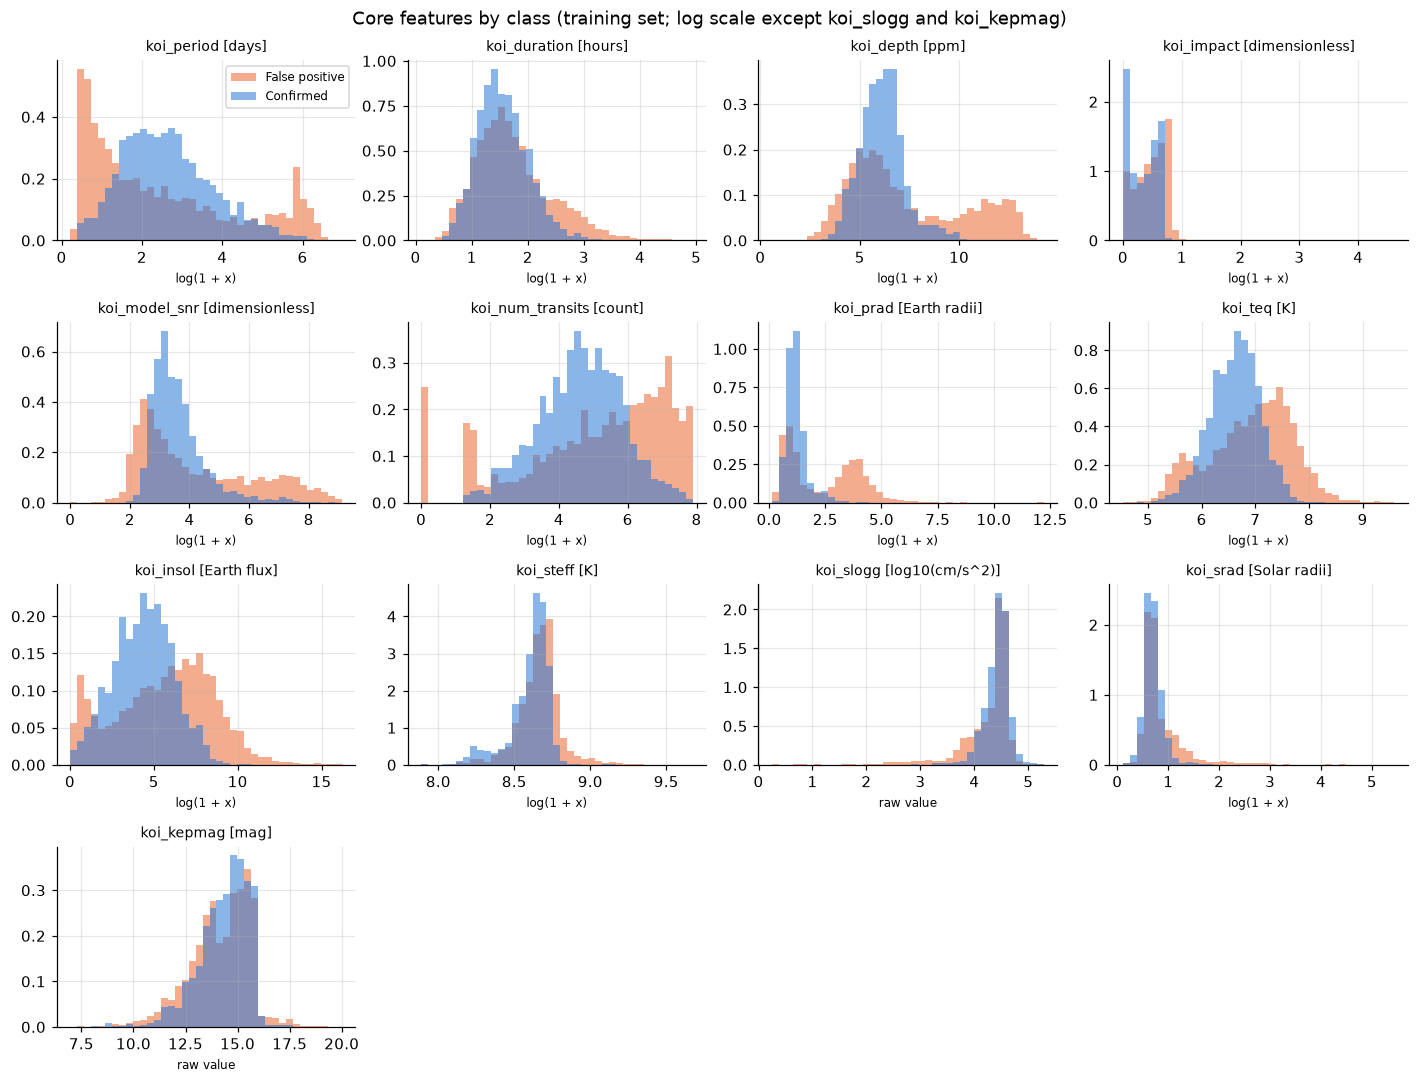

In [85]:
fig, axes = plt.subplots(4, 4, figsize=(13, 10))
for ax, col in zip(axes.flat, CORE_FEATURES):
    log_scale = col not in LINEAR_FEATURES
    values = np.log1p(train[col]) if log_scale else train[col]
    bins = np.linspace(values.min(), values.max(), 40)
    for label in (0, 1):
        ax.hist(values[train["y"] == label].dropna(), bins=bins, density=True, alpha=0.55,
                color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.set_title(f"{col} [{FEATURE_UNITS[col]}]", fontsize=9)
    ax.set_xlabel("log(1 + x)" if log_scale else "raw value", fontsize=8)
for ax in axes.flat[len(CORE_FEATURES):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=8)
fig.suptitle("Core features by class (training set; log scale except koi_slogg and koi_kepmag)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distributions_by_class.png", bbox_inches="tight")

In [86]:
physical_checks = {
    "koi_prad > 30 (Earth radii)": train["koi_prad"] > 30,
    "koi_impact > 1 (grazing)": train["koi_impact"] > 1,
    "koi_depth > 1e5 (ppm)": train["koi_depth"] > 1e5,
}
pd.DataFrame({
    "rows": {k: m.sum() for k, m in physical_checks.items()},
    "share_of_train": {k: m.mean() for k, m in physical_checks.items()},
    "share_confirmed": {k: train.loc[m, "y"].mean() for k, m in physical_checks.items()},
}).assign(overall_prevalence=train["y"].mean()).round(3)

,rows,share_of_train,share_confirmed,overall_prevalence
koi_prad > 30 (Earth radii),1264,0.208,0.002,0.362
koi_impact > 1 (grazing),966,0.159,0.012,0.362
koi_depth > 1e5 (ppm),529,0.087,0.000,0.362


**Decision:** nothing deleted and nothing capped. Long tailed features get a log transform in the pipeline. It has to work at zero because `koi_impact`, `koi_model_snr` and `koi_num_transits` have exact zeros, but nothing is negative.

What surprised me is that the "outliers" aren't rare errors at all. They're a big, consistent false positive pattern:

* **Planet radius over 30 Earth radii:** 1,264 rows, about 21% of training, and only 0.2% confirmed. Nothing that big is a planet. These are almost certainly stars eclipsing each other.
* **Impact over 1:** 966 rows, about 16%, and 1.2% confirmed. Grazing eclipses are typical of binary stars, and impacts up to 100 just mean the fit went badly.
* **Depth over 100,000 ppm:** 529 rows, about 9%, and none confirmed. A star dimming by more than 10% is almost always another star.

Deleting these would remove exactly what the model needs to learn. The histograms tell the same story: false positives own the long tails of depth, radius and SNR.

## 8. Leakage analysis

This is the part I care most about, because leakage gives results that look great and mean nothing. I check it three ways: the known vetting outputs, a scan of every numeric column, and two specific risks, where the stellar data came from and `koi_count`. Training set only.

### 8A. Known leaks

These come straight from the column documentation, and the full list is in the leakage register at the end of this section. Three of them, `koi_vet_stat`, `koi_vet_date` and `koi_disp_prov`, only have one value in this download, so section 2 calls them constant.

In [87]:
def leak_reason(col):
    if col in LEAKY_COLUMNS:
        return LEAKY_COLUMNS[col]
    return next(reason for prefix, reason in LEAKY_PREFIXES.items() if col.startswith(prefix))


leaky_present = [c for c in df.columns if is_leaky(c)]
print(f"{len(leaky_present)} leaky columns present in the table")
pd.Series([leak_reason(c) for c in leaky_present]).value_counts().rename("columns").to_frame()

43 leaky columns present in the table


,columns
centroid diagnostic (feeds koi_fpflag_co),25
stellar uncertainty reflects follow-up effort,4
false-positive flag (vetting output),4
metallicity mostly measured during follow-up,3
only assigned once a planet is confirmed,1
vetting status,1
Kepler pipeline disposition (vetting output),1
vetting comment text,1
vetting date,1
disposition provenance,1


### 8B. Scanning every column on its own

Each numeric column is used alone in a small decision tree and scored with grouped cross-validation on the training set. I use a tree rather than plain ROC-AUC because it also picks up U shaped patterns and signal hiding in missing values.

A high score doesn't automatically mean leakage. `koi_prad` should be strong. The question for each strong column is why.

In [88]:
role_by_column = dictionary.set_index("column")["role"]
numeric_columns_to_scan = [column for column in train.columns
                           if column in role_by_column and pd.api.types.is_numeric_dtype(train[column])
                           and role_by_column[column] not in ("empty", "constant", "id", "target")]

grouped_cv_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                         .split(train, train["y"], groups=train[GROUP]))
single_column_probe_model = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True),
    DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
)

column_scan_results = pd.DataFrame([
    {"column": column, "role": role_by_column[column],
     "cv_roc_auc": cross_val_score(single_column_probe_model, train[[column]], train["y"],
                                   cv=grouped_cv_splits, scoring="roc_auc").mean()}
    for column in numeric_columns_to_scan
]).sort_values("cv_roc_auc", ascending=False, ignore_index=True)
print(f"Scanned {len(column_scan_results)} numeric columns")
column_scan_results[column_scan_results["role"].isin(["core feature", "sensitivity"])].round(3)

Scanned 103 numeric columns


,column,role,cv_roc_auc
6,koi_prad,core feature,0.799
29,koi_num_transits,core feature,0.747
40,koi_model_snr,core feature,0.738
42,koi_count,sensitivity,0.735
50,koi_period,core feature,0.721
51,koi_insol,core feature,0.718
53,koi_teq,core feature,0.717
58,koi_depth,core feature,0.711
65,koi_impact,core feature,0.698
82,koi_steff,core feature,0.627


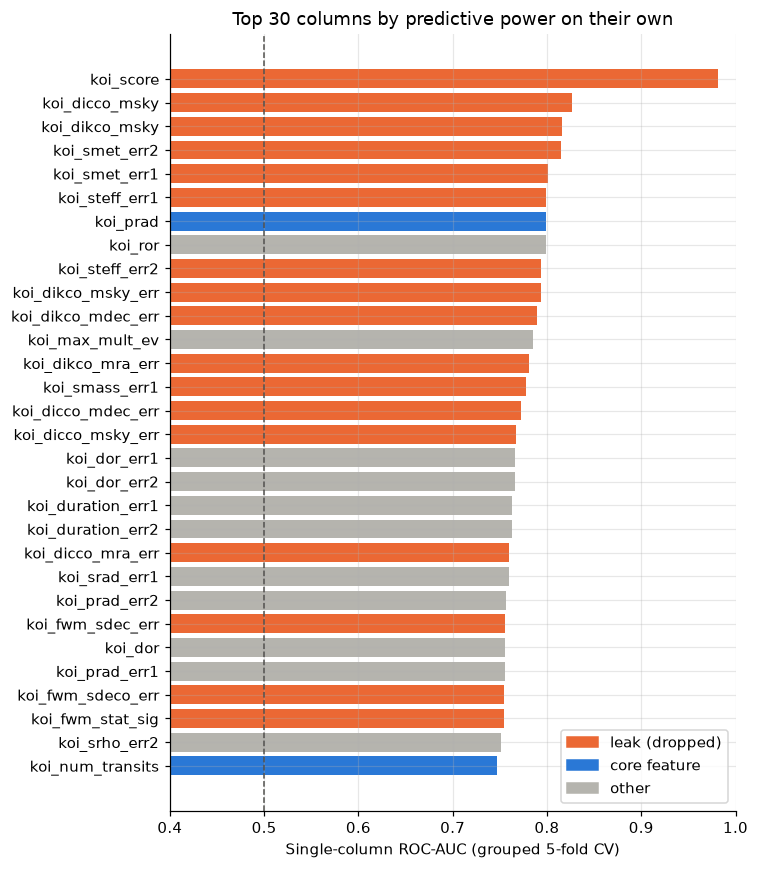

In [89]:
top_columns_for_plot = column_scan_results.head(30).iloc[::-1]
role_colors = {"leak": "#eb6834", "core feature": "#2a78d6"}
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(top_columns_for_plot["column"], top_columns_for_plot["cv_roc_auc"],
        color=[role_colors.get(role, "#b5b4ae") for role in top_columns_for_plot["role"]])
ax.axvline(0.5, color="#52514e", lw=1, ls="--")
ax.set(xlim=(0.4, 1), xlabel="Single-column ROC-AUC (grouped 5-fold CV)",
       title="Top 30 columns by predictive power on their own")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in [*role_colors.values(), "#b5b4ae"]],
          labels=["leak (dropped)", "core feature", "other"], loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_leakage_scan.png", bbox_inches="tight")

In [90]:
SUSPICIOUS_AUC = 0.75
suspicious_columns = column_scan_results[
    (column_scan_results["cv_roc_auc"] > SUSPICIOUS_AUC)
    & (column_scan_results["role"] != "leak")
]
suspicious_columns.round(3)

,column,role,cv_roc_auc
6,koi_prad,core feature,0.799
7,koi_ror,other numeric,0.799
11,koi_max_mult_ev,other numeric,0.786
16,koi_dor_err1,other numeric,0.766
17,koi_dor_err2,other numeric,0.766
18,koi_duration_err1,other numeric,0.763
19,koi_duration_err2,other numeric,0.762
21,koi_srad_err1,other numeric,0.760
22,koi_prad_err2,other numeric,0.756
24,koi_dor,other numeric,0.755


The scan works: `koi_score`, NASA's own verdict, comes top at 0.98, and the centroid and stellar uncertainty columns I'd already dropped fill most of the top 30. Of the columns that are left:

* `koi_prad` scores 0.80 for a real reason, since false positives are often too big to be planets. `koi_ror`, the planet to star size ratio, scores the same without using the star's radius at all, which tells me the signal is genuine and not a side effect of the stellar data in 8C.
* `koi_max_mult_ev` scores 0.79. It's how strongly the pipeline detected the signal, so it's physical, and it isn't one of my features anyway.
* Uncertainty columns score 0.75 to 0.77. Messy signals that don't look like planets get bigger fit errors, so that's mostly physical too. The odd one out is `koi_srad_err1`, which probably reflects follow-up effort like the stellar errors I already dropped. It's not a feature, so it can't affect the models.
* `koi_num_transits` sits just under the cut-off. Its strength comes from the orbital period and from its missing values, and both are legitimate.

None of my 13 features look leaky, so the feature set stays as it is.

### 8C. Where did the stellar data come from?

If confirmed planets had their host stars measured differently, the stellar values themselves could give the answer away, not just their error bars. `koi_sparprov` records the source.

In [91]:
stellar_source_summary = (train.groupby("koi_sparprov", dropna=False)["y"]
                          .agg(rows="size", share_confirmed="mean")
                          .sort_values("rows", ascending=False))
stellar_source_summary["overall_prevalence"] = train["y"].mean()
stellar_source_summary.round(3)

,rows,share_confirmed,overall_prevalence
koi_sparprov,,,
q1_q17_dr25_stellar,5242,0.416,0.362
stellar_q1_q16,435,0.028,0.362
NaN,207,0.010,0.362
stellar_q1_q17,107,0.009,0.362
Solar,77,0.000,0.362


In [92]:
uses_final_dr25_catalog = train["koi_sparprov"] == "q1_q17_dr25_stellar"
is_false_positive = train["y"] == 0
print(f"Rows from other stellar sources: {(~uses_final_dr25_catalog).sum():,} "
      f"({(~uses_final_dr25_catalog).mean():.1%} of training rows), "
      f"{train.loc[~uses_final_dr25_catalog, 'y'].sum()} of them confirmed")
print(f"Share of all false positives in this group: "
      f"{(is_false_positive & ~uses_final_dr25_catalog).sum() / is_false_positive.sum():.1%}")
train.loc[train["koi_sparprov"] == "Solar", ["koi_steff", "koi_slogg", "koi_srad"]].agg(["min", "max"])

Rows from other stellar sources: 826 (13.6% of training rows), 15 of them confirmed
Share of all false positives in this group: 21.0%


,koi_steff,koi_slogg,koi_srad
min,5780.0,4.438,1.0
max,5780.0,4.438,1.0


This was the biggest surprise in the audit. 41.6% of the 5,242 rows using the final DR25 stellar catalogue are confirmed, but only 3% or less of the other 826. Those come from older catalogues, from default solar values, or have no stellar solution at all. All 77 `Solar` rows have exactly the Sun's values, so they're placeholders rather than measurements.

The 826 rows are about 14% of training and 21% of all false positives. My best explanation is history rather than physics: KOIs rejected early were never measured again with the final catalogue. So the stellar features, and `koi_prad`, which is worked out from the star's radius, can partly give the answer away through their source. My baseline scores may be slightly optimistic because of this.

**Decision for now:** keep all rows and flag it here and in the README. In Milestone 3 I'll measure the effect by comparing the model on all rows against DR25 rows only, and with and without the stellar features.

### 8D. `koi_count`, the number of KOIs on the same star

In [93]:
train.groupby("koi_count")["y"].agg(rows="size", share_confirmed="mean").round(3)

,rows,share_confirmed
koi_count,,
1,4622,0.224
2,787,0.696
3,356,0.941
4,185,0.930
5,97,0.907
6,17,0.941
7,4,0.750


**Decision:** `koi_count` stays out of the main model and gets tested separately.

Only 22% of single KOI stars are confirmed, against 70% to 94% for stars with several. Part of that is real, but part of it is because astronomers use multiplicity as evidence when confirming planets, so the vetting decision feeds back into the feature. The count also includes KOIs found later, which a real prediction wouldn't know about. In Milestone 3 I'll show how much it would add.

### Leakage register

Every dropped or excluded column, the reason, and the evidence from the scan. Saved to `reports/leakage_register.csv`.

In [94]:
roc_auc_by_column = column_scan_results.set_index("column")["cv_roc_auc"]
register = pd.DataFrame(
    [{"column": column, "reason": leak_reason(column),
      "evidence_cv_roc_auc": roc_auc_by_column.get(column), "decision": "drop"}
     for column in leaky_present]
    + [{"column": column, "reason": "multiplicity used when validating planets; includes later KOIs",
        "evidence_cv_roc_auc": roc_auc_by_column.get(column),
        "decision": "exclude from main model; sensitivity test"}
       for column in SENSITIVITY_FEATURES]
)
register.to_csv(REPORTS / "leakage_register.csv", index=False)
register.round(3)

,column,reason,evidence_cv_roc_auc,decision
0,kepler_name,only assigned once a planet is confirmed,NaN,drop
1,koi_vet_stat,vetting status,NaN,drop
2,koi_pdisposition,Kepler pipeline disposition (vetting output),NaN,drop
3,koi_steff_err1,stellar uncertainty reflects follow-up effort,0.799,drop
4,koi_steff_err2,stellar uncertainty reflects follow-up effort,0.794,drop
5,koi_smet,metallicity mostly measured during follow-up,0.723,drop
6,koi_smet_err1,metallicity mostly measured during follow-up,0.801,drop
7,koi_smet_err2,metallicity mostly measured during follow-up,0.815,drop
8,koi_smass_err1,stellar uncertainty reflects follow-up effort,0.778,drop
9,koi_smass_err2,stellar uncertainty reflects follow-up effort,0.745,drop


## 9. How related are the core features?

Spearman correlation on the training set, since the features are skewed and full of extreme values.

koi_teq           koi_insol           1.00
koi_slogg         koi_srad           -0.98
koi_period        koi_num_transits   -0.92
                  koi_teq            -0.89
                  koi_insol          -0.89
koi_depth         koi_prad            0.81
koi_num_transits  koi_teq             0.80
                  koi_insol           0.80
dtype: float64

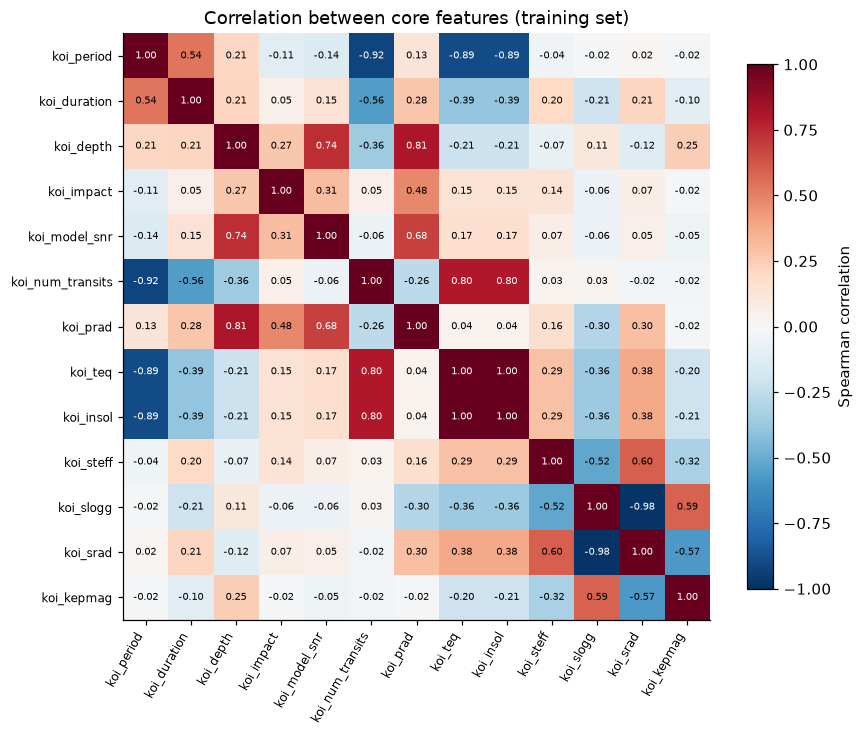

In [95]:
corr = train[CORE_FEATURES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(len(corr)), yticks=range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iat[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Correlation between core features (training set)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_correlation.png", bbox_inches="tight")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(2)

**Decision:** keep all 13 for now.

Every strong pair has a physical reason behind it:

* **`koi_teq` and `koi_insol`, 1.00:** both are calculated from the same inputs, so they carry the same information.
* **`koi_slogg` and `koi_srad`, −0.98:** bigger stars have weaker surface gravity.
* **`koi_period` and `koi_num_transits`, −0.92:** a longer orbit fits fewer transits into Kepler's four years.
* **`koi_period` with `koi_teq` and `koi_insol`, −0.89:** longer orbits are further out and cooler.
* **`koi_depth` and `koi_prad`, 0.81:** planet radius is worked out from the transit depth.

Trees don't mind this, but logistic regression coefficients for these pairs can't be read on their own, so I'll use permutation importance in Milestone 3. Keeping only one of `koi_teq` and `koi_insol` is an easy simplification to try.

## 10. Final feature list and drop list

In [96]:
final = dictionary["role"].map(lambda r: "kept: core feature" if r == "core feature"
                               else "kept: sensitivity test only" if r == "sensitivity"
                               else f"dropped: {r}")
print(f"Total columns: {len(dictionary)}")
final.value_counts()

Total columns: 153


role
dropped: other numeric         52
dropped: leak                  40
dropped: empty                 24
kept: core feature             13
dropped: constant              11
dropped: metadata               7
dropped: id                     4
dropped: target                 1
kept: sensitivity test only     1
Name: count, dtype: int64

Everything is saved in `src/features.py`.

**Preprocessing plan**, built in notebook 02:

* All 13 features are numeric. The long tailed ones get a log transform, except `koi_slogg` and `koi_kepmag` which are already on a log scale. Then scaling, then median imputation with missing value indicators, all fitted on training folds only.
* No categorical features, since all 20 text columns are IDs, metadata, leaks or the target.

## Key findings

1. **153 columns down to 13,** plus `koi_count` for a separate test. Dropped: 24 empty, 11 constant, 4 ID, 7 metadata and 40 leaky columns, plus 52 numeric columns outside the core set.
2. **Group by star.** 7,587 labelled KOIs, 36.2% confirmed, and 938 stars with several KOIs. Train and test are 6,068 and 1,519 rows with the same class balance.
3. **Missing values are a clue.** The 207 rows with no transit fit are 99% false positives.
4. **Extreme values are signal.** Huge radii, grazing impacts and very deep dips cover 9% to 21% of training rows and are almost never confirmed.
5. **Leakage.** Vetting outputs, centroid checks and stellar error bars are dropped, and the scan confirms `koi_score` as the biggest giveaway at 0.98. Two subtler risks are still being tested: `koi_count` and where the stellar data came from.